# 10. 전처리 방법 비교 시리즈 1단계(P1, Validation만)

지금까지는 모두 **letterbox 224**(비율 유지 + 평균색 패딩)로 학습했습니다. 이 노트북은 전처리만 바꾸고 나머지 조건은 최종 후보 A(Full FT)와 똑같이 두어 비교합니다.

| 이름 | 입력 | 만드는 법 | 보려는 것 |
|---|---|---|---|
| letterbox(기준) | 224×224 | 224×126으로 줄이고 위아래 49px 패딩 | — |
| stretch | 224×224 | 비율을 무시하고 늘림(세로 1.78배) | 왜곡의 영향. 세로 해상도는 오히려 늘어남 |
| aspect224 | 224×126 | 비율 유지 축소, 패딩 없음 | 패딩이 해가 되는가(내용 픽셀은 letterbox와 같음) |
| aspect384 | 384×216 | 원본 그대로 | 384 letterbox(SEL-C)의 바벨 로우 붕괴가 해상도 탓인가, 패딩 탓인가 |
| ccrop | 224×224 | 가운데 216×216을 잘라 224로 | 양옆 배경을 잘라 낸 영향 |
| gray | 224×224 | letterbox 뒤 흑백(3채널 복제) | 색 정보의 기여 |

- **Test는 쓰지 않습니다.** 공식 최종 결과는 E08(Test Macro F1 0.839) 그대로이고, 이 시리즈는 Val 기준 추가 분석입니다.
- 전처리마다 Full을 seed 42·43·44로 3회, Scratch는 seed 42로 1회 돌렸습니다.
- **판정 기준(실행 전 `experiments/P1/PLAN.md`)**
  1. Full 3회 중 2회 이상 어떤 클래스든 Recall < 0.20이면 "붕괴 경향"으로 보고, "좋음"으로 판정하지 않습니다.
  2. 차이 d = 평균 − 0.8736(후보 A), 기준 t = max(표준편차, 0.0138)로 둡니다. d > t면 좋음, d < −t면 나쁨, 그 사이면 구분 불가입니다.
  3. Scratch는 1회라 판정하지 않고 참고로만 봅니다.
  4. "좋음"은 seed 2개를 더 돌려 다시 확인한 뒤에만 채택합니다(비교가 5개라 우연히 넘을 수 있음).

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from PIL import Image

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src"))
from common import DATA_RAW, FIGURES, FIGURES_SAMPLES, GROUPS, class_names, set_korean_font
from dataset import IMAGENET_MEAN, IMAGENET_STD, build_transforms, load_split

print("font:", set_korean_font())
pd.set_option("display.width", 220)
NAMES = class_names()
EXP = ROOT / "experiments"
PRE = {"letterbox": ("letterbox", 224), "stretch": ("stretch", 224), "aspect224": ("aspect", 224),
       "aspect384": ("aspect", 384), "ccrop": ("ccrop", 224), "gray": ("gray", 224)}
FULL = {"letterbox": ["E04", "SEL-A-s43", "SEL-A-s44"],
        **{n: [f"P1-{n}-s{s}" for s in (42, 43, 44)] for n in PRE if n != "letterbox"}}
SCR = {"letterbox": "E01", **{n: f"P1-{n}-s42" for n in PRE if n != "letterbox"}}
BASE_MEAN, BASE_SD = 0.8736, 0.0138  # 후보 A(PLAN에 적은 값)

def load(rid, strat):
    d = EXP / rid / strat
    return (json.loads((d / "summary.json").read_text(encoding="utf-8")),
            json.loads((d / "config.json").read_text(encoding="utf-8")), pd.read_csv(d / "history.csv"))

rows = []
for name, rids in FULL.items():
    for rid in rids:
        sm, cf, h = load(rid, "full")
        assert cf.get("preprocess", "letterbox") == PRE[name][0] and cf.get("input_size", 224) == PRE[name][1], rid
        assert (cf.get("augment") or "none") == "none" and (cf.get("class_weight") or "none") == "none", rid
        rec = sm["val"]["per_class"]["recall"]
        worst = min(rec, key=rec.get)
        rows.append({"전처리": name, "seed": cf["seed"], "실행": rid, "Val Macro F1": sm["val"]["macro_f1"], "Val Acc": sm["val"]["accuracy"],
                     "최저 Recall": rec[worst], "최저 클래스": worst, "덤벨 로우": rec["덤벨 벤트오버 로우"], "데드리프트": rec["바벨 데드리프트"],
                     "바벨 로우": rec["바벨 로우"], "최고/멈춘 epoch": f"{sm['best_epoch']}/{sm['epochs_run']}",
                     "epoch당 학습(초)": sm["mean_train_epoch_s"], "GPU(MB)": sm["peak_gpu_mem_mb"], "전체(분)": sm["total_time_s"] / 60})
runs = pd.DataFrame(rows)
runs.round(3)

font: Malgun Gothic


,전처리,seed,실행,Val Macro F1,Val Acc,최저 Recall,최저 클래스,덤벨 로우,데드리프트,바벨 로우,최고/멈춘 epoch,epoch당 학습(초),GPU(MB),전체(분)
0,letterbox,42,E04,0.858,0.866,0.400,바벨 데드리프트,0.794,0.400,0.531,16/21,10.227,628.713,4.385
1,letterbox,43,SEL-A-s43,0.878,0.887,0.484,바벨 로우,0.775,0.594,0.484,8/13,10.789,628.713,2.837
2,letterbox,44,SEL-A-s44,0.884,0.897,0.531,바벨 로우,0.912,0.544,0.531,7/12,10.703,628.713,2.596
3,stretch,42,P1-stretch-s42,0.857,0.861,0.425,바벨 데드리프트,0.631,0.425,0.500,3/8,11.269,628.713,1.797
4,stretch,43,P1-stretch-s43,0.865,0.874,0.262,바벨 데드리프트,0.862,0.262,0.719,6/11,10.341,628.713,2.296
5,stretch,44,P1-stretch-s44,0.879,0.894,0.391,바벨 로우,0.894,0.531,0.391,5/10,10.439,628.713,2.103
6,aspect224,42,P1-aspect224-s42,0.820,0.844,0.188,바벨 로우,0.812,0.419,0.188,2/7,8.275,466.256,1.178
7,aspect224,43,P1-aspect224-s43,0.866,0.881,0.359,바벨 로우,0.794,0.688,0.359,12/17,7.286,466.256,2.705
8,aspect224,44,P1-aspect224-s44,0.854,0.879,0.281,바벨 로우,0.762,0.738,0.281,4/9,8.157,466.256,1.544
9,aspect384,42,P1-aspect384-s42,0.864,0.894,0.141,바벨 로우,0.944,0.788,0.141,2/7,15.862,874.212,2.117


## 0. 전처리별로 같은 사진이 어떻게 들어가는가

In [2]:
img = Image.open(DATA_RAW / load_split("train").loc[0, "image_path"]).convert("RGB")
mean, std = torch.tensor(IMAGENET_MEAN).view(3, 1, 1), torch.tensor(IMAGENET_STD).view(3, 1, 1)
fig, axes = plt.subplots(1, 6, figsize=(22, 4))
for ax, (name, (pre, size)) in zip(axes, PRE.items()):
    x = build_transforms(size, preprocess=pre)[1](img) * std + mean      # 모델에 들어가는 텐서를 다시 그림으로
    ax.imshow(x.permute(1, 2, 0).clamp(0, 1).numpy()); ax.set_title(f"{name} {x.shape[2]}×{x.shape[1]}")
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIGURES_SAMPLES / "p1_preview.jpg", dpi=80); plt.show()

[원본 사진 그림 출력은 지웠습니다. 로컬 파일 figures/samples/에 저장되어 있고, 공개 저장소에는 넣지 않습니다(AI Hub 이용 조건).]


## 1. 판정(Full, seed 3회)

In [3]:
agg = runs.groupby("전처리", sort=False).agg(평균=("Val Macro F1", "mean"), 표준편차=("Val Macro F1", "std"),
                                            최소=("Val Macro F1", "min"), 최대=("Val Macro F1", "max"), Acc_평균=("Val Acc", "mean"),
                                            붕괴_횟수=("최저 Recall", lambda x: int((x < 0.20).sum())),
                                            덤벨로우=("덤벨 로우", "mean"), 데드리프트=("데드리프트", "mean"), 바벨로우=("바벨 로우", "mean"),
                                            epoch당_초=("epoch당 학습(초)", "mean"), GPU_MB=("GPU(MB)", "max"))
assert abs(agg.loc["letterbox", "평균"] - BASE_MEAN) < 5e-5 and abs(agg.loc["letterbox", "표준편차"] - BASE_SD) < 5e-5
agg["d"] = agg["평균"] - BASE_MEAN
agg["t"] = np.maximum(agg["표준편차"], BASE_SD)
def verdict(r):
    if r.name == "letterbox":
        return "기준"
    v = "좋음" if r.d > r.t else ("나쁨" if r.d < -r.t else "구분 불가")
    if r.붕괴_횟수 >= 2:
        v = ("붕괴 경향(좋음 불가)" if v == "좋음" else f"{v}, 붕괴 경향")
    return v
agg["판정"] = agg.apply(verdict, axis=1)
agg.round(4)

,평균,표준편차,최소,최대,Acc_평균,붕괴_횟수,덤벨로우,데드리프트,바벨로우,epoch당_초,GPU_MB,d,t,판정
전처리,,,,,,,,,,,,,,
letterbox,0.8736,0.0138,0.8581,0.8845,0.8831,0,0.8271,0.5125,0.5156,10.5729,628.7129,-0.0000,0.0138,기준
stretch,0.8672,0.0113,0.8573,0.8794,0.8762,0,0.7958,0.4062,0.5365,10.6830,628.7129,-0.0064,0.0138,구분 불가
aspect224,0.8467,0.0242,0.8197,0.8664,0.8681,1,0.7896,0.6146,0.2760,7.9058,466.2559,-0.0269,0.0242,나쁨
aspect384,0.8756,0.0166,0.8635,0.8945,0.9009,2,0.8333,0.8167,0.2292,15.6638,874.2124,0.0020,0.0166,"구분 불가, 붕괴 경향"
ccrop,0.8959,0.0127,0.8837,0.9090,0.9183,0,0.8458,0.8333,0.3281,10.4199,628.7129,0.0223,0.0138,좋음
gray,0.8228,0.0110,0.8145,0.8354,0.8375,0,0.5104,0.5854,0.4219,11.1264,628.7129,-0.0508,0.0138,나쁨


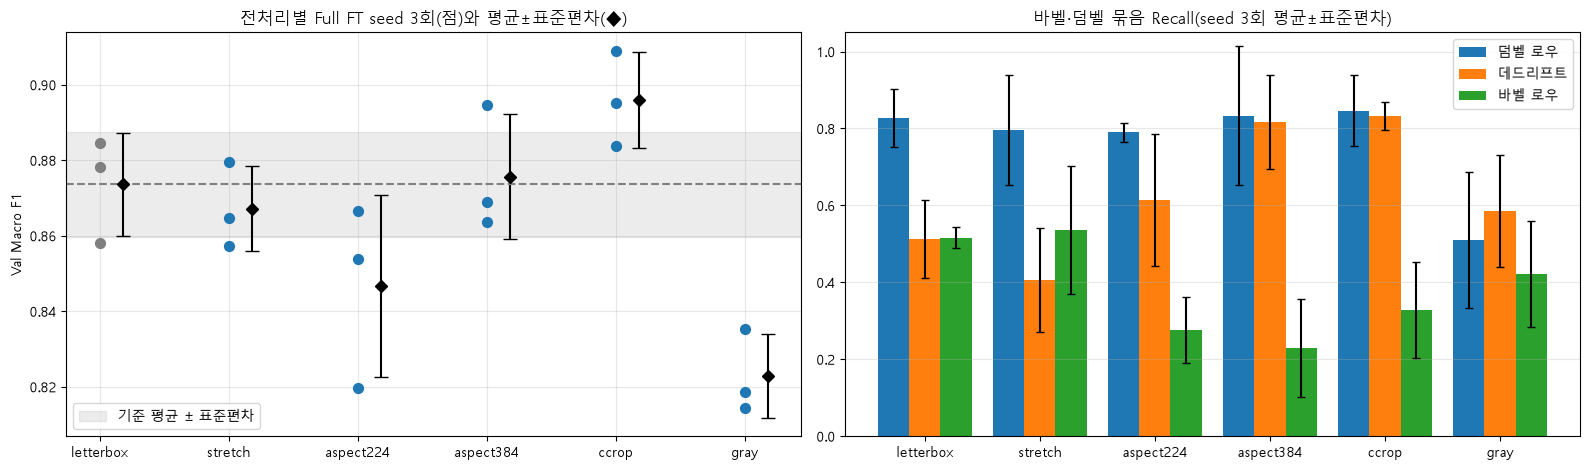

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
names = list(PRE)
for i, n in enumerate(names):
    g = runs[runs["전처리"] == n]
    axes[0].scatter([i] * len(g), g["Val Macro F1"], s=50, zorder=3, color="gray" if n == "letterbox" else "C0")
    axes[0].errorbar(i + 0.18, g["Val Macro F1"].mean(), yerr=g["Val Macro F1"].std(), fmt="D", color="k", capsize=5)
axes[0].axhspan(BASE_MEAN - BASE_SD, BASE_MEAN + BASE_SD, color="gray", alpha=.15, label="기준 평균 ± 표준편차")
axes[0].axhline(BASE_MEAN, color="gray", ls="--")
axes[0].set_xticks(range(len(names))); axes[0].set_xticklabels(names); axes[0].set_ylabel("Val Macro F1"); axes[0].legend(loc="lower left")
axes[0].set_title("전처리별 Full FT seed 3회(점)와 평균±표준편차(◆)"); axes[0].grid(alpha=.3)
x = np.arange(len(names)); w = 0.27
for k, cls in enumerate(("덤벨 로우", "데드리프트", "바벨 로우")):
    m = runs.groupby("전처리", sort=False)[cls].mean(); s = runs.groupby("전처리", sort=False)[cls].std()
    axes[1].bar(x + (k - 1) * w, m.values, w, yerr=s.values, capsize=3, label=cls)
axes[1].set_xticks(x); axes[1].set_xticklabels(names); axes[1].set_ylim(0, 1.05); axes[1].legend()
axes[1].set_title("바벨·덤벨 묶음 Recall(seed 3회 평균±표준편차)"); axes[1].grid(alpha=.3, axis="y")
plt.tight_layout(); plt.savefig(FIGURES / "p1_preprocessing.png", dpi=110); plt.show()

## 2. 클래스별로 보기

In [5]:
order = [c for g in GROUPS.values() for c in g]
tab = {}
for n, rids in FULL.items():
    r = np.array([[load(rid, "full")[0]["val"]["per_class"]["recall"][NAMES[c]] for c in order] for rid in rids])
    tab[n] = [f"{m:.2f}±{s:.2f}" for m, s in zip(r.mean(0), r.std(0, ddof=1))]
print("클래스별 Val Recall(Full, seed 3회 평균±표준편차)")
pd.DataFrame(tab, index=[f"{c} {NAMES[c]}" for c in order])

클래스별 Val Recall(Full, seed 3회 평균±표준편차)


,letterbox,stretch,aspect224,aspect384,ccrop,gray
0 Y - Exercise,0.97±0.00,0.98±0.02,0.94±0.04,0.98±0.00,0.98±0.01,0.96±0.05
1 니푸쉬업,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00
4 라잉 레그 레이즈,0.91±0.05,0.92±0.00,0.94±0.04,0.92±0.09,0.91±0.07,0.88±0.02
10 바이시클 크런치,0.93±0.04,0.95±0.04,0.83±0.05,0.88±0.15,0.92±0.04,0.73±0.17
2 덤벨 벤트오버 로우,0.83±0.07,0.80±0.14,0.79±0.03,0.83±0.18,0.85±0.09,0.51±0.18
7 바벨 데드리프트,0.51±0.10,0.41±0.14,0.61±0.17,0.82±0.12,0.83±0.04,0.59±0.14
8 바벨 런지,0.94±0.01,0.98±0.01,0.92±0.06,0.91±0.08,0.98±0.01,0.94±0.04
9 바벨 로우,0.52±0.03,0.54±0.17,0.28±0.09,0.23±0.13,0.33±0.12,0.42±0.14
3 딥스,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00,1.00±0.00
5 랫풀 다운,0.98±0.00,0.98±0.01,0.98±0.00,0.98±0.00,0.98±0.00,0.98±0.00


## 3. Scratch(seed 1회, 참고)

In [6]:
rows = []
for n, rid in SCR.items():
    sm, cf, h = load(rid, "scratch")
    assert cf.get("preprocess", "letterbox") == PRE[n][0] and cf.get("input_size", 224) == PRE[n][1] and cf["seed"] == 42, rid
    rows.append({"전처리": n, "실행": rid, "Val Macro F1": sm["val"]["macro_f1"], "Val Acc": sm["val"]["accuracy"],
                 "E01 대비": sm["val"]["macro_f1"] - 0.7928 if n != "letterbox" else np.nan,
                 "바벨 로우 Recall": sm["val"]["per_class"]["recall"]["바벨 로우"],
                 "최고/멈춘 epoch": f"{sm['best_epoch']}/{sm['epochs_run']}", "epoch당 학습(초)": sm["mean_train_epoch_s"]})
print("Scratch는 seed 1회라 판정하지 않습니다(같은 조건에서도 seed만으로 0.02 넘게 흔들릴 수 있음)")
pd.DataFrame(rows).round(4)

Scratch는 seed 1회라 판정하지 않습니다(같은 조건에서도 seed만으로 0.02 넘게 흔들릴 수 있음)


,전처리,실행,Val Macro F1,Val Acc,E01 대비,바벨 로우 Recall,최고/멈춘 epoch,epoch당 학습(초)
0,letterbox,E01,0.7928,0.7979,NaN,0.5000,9/14,10.7243
1,stretch,P1-stretch-s42,0.7338,0.7583,-0.0590,0.2344,6/11,10.2375
2,aspect224,P1-aspect224-s42,0.7716,0.7924,-0.0212,0.4375,10/15,7.2593
3,aspect384,P1-aspect384-s42,0.7898,0.8167,-0.0030,0.3281,14/19,14.3213
4,ccrop,P1-ccrop-s42,0.7675,0.8132,-0.0253,0.3281,7/12,10.4291
5,gray,P1-gray-s42,0.7409,0.7694,-0.0519,0.4844,8/13,10.6362


## 4. 해석

### 4.1 판정(실행 전 기준 그대로)

| 전처리 | Full 평균 ± 표준편차 | 기준 대비 | 판정 | 실행 전 예측 | epoch당 학습 |
|---|---|---|---|---|---|
| letterbox(기준) | 0.874 ± 0.014 | — | 기준 | — | 10.6초 |
| stretch | 0.867 ± 0.011 | −0.006 | 구분 불가 | 구분 불가 (맞음) | 10.7초 |
| aspect224 | 0.847 ± 0.024 | −0.027 | 나쁨 | 구분 불가 (틀림) | **7.9초** |
| aspect384 | 0.876 ± 0.017 | +0.002 | 구분 불가, 붕괴 경향 | 바벨 로우 붕괴 (맞음) | 15.7초 |
| **ccrop** | **0.896 ± 0.013** | **+0.022** | **좋음** | 나쁨 (틀림) | 10.4초 |
| gray | 0.823 ± 0.011 | −0.051 | 나쁨 | 구분 불가~약간 나쁨 (일부 맞음) | 11.1초 |

- 계획대로 "좋음"인 ccrop도 바로 채택하지 않습니다. 비교가 5개라 우연히 넘을 수 있기 때문입니다. 재확인은 사람 단위 교차검증(D-037)에서 합니다.

### 4.2 가운데 자르기(ccrop)가 왜 좋았나: 예측이 틀린 이유

- 예측은 "양옆이 잘려 사람이 잘리면 나빠진다"였습니다. 결과는 반대로 Macro F1이 가장 높았고(0.896), 데드리프트 Recall이 0.51 → 0.83으로 크게 올랐습니다.
- ccrop은 두 가지를 동시에 바꿉니다.
  1. **양옆 배경을 잘라 냅니다.**
  2. **사람이 크게 들어갑니다.** 216×216을 224로 키우므로 원본 픽셀이 약 1.04배로 들어갑니다. letterbox는 0.58배로 줄여서 넣습니다. 사람 크기로 보면 384 입력과 비슷해집니다.
- 384 입력(aspect384, SEL-C)도 데드리프트가 크게 오르고 바벨 로우가 내려갔습니다. ccrop의 클래스별 모양(데드리프트 0.83, 바벨 로우 0.33)이 이와 닮았습니다. 그래서 **효과의 상당 부분은 "사람을 크게 보는 것"으로 보입니다(가설).** 이 실험만으로는 배경 제거 효과와 확대 효과를 나눌 수 없습니다.
- ccrop은 384와 달리 바벨 로우가 통째로 무너지지는 않았습니다(최저 0.20). 계산량은 letterbox와 같습니다.

### 4.3 나머지 전처리

- **aspect384(원본 그대로)**: 384 letterbox(SEL-C, 0.880)와 거의 같고, 바벨 로우가 3번 중 2번 무너진 것도 같습니다. 그래서 **SEL-C의 바벨 로우 붕괴는 패딩 때문이 아니라 해상도(사람 크기) 때문**입니다. 실행 전 예측대로입니다.
- **aspect224(패딩만 뺌)**: 내용 픽셀이 letterbox와 똑같은데 0.027 낮았습니다. 예측과 다릅니다.
  - 차이는 출력 특징 지도 모양(7×7 → 4×7)과, 평균 풀링에 패딩 칸이 섞이는지 여부뿐입니다.
  - 다만 표준편차가 0.024로 커서(seed 42는 2 epoch에 최고점) 우연일 수 있습니다. 교차검증에서 다시 봅니다.
  - 계산은 가장 빨랐습니다(epoch당 7.9초, 기준의 0.75배, GPU 메모리 466MB).
- **stretch(늘리기)**: 구분 불가입니다. 세로로 1.78배 늘려도 성능이 크게 변하지 않았습니다. CNN이 이 정도 비율 왜곡에는 꽤 견딘다는 뜻입니다.
- **gray(흑백)**: 가장 나빴습니다(−0.051). 덤벨 로우 Recall이 0.83 → 0.51로 떨어졌습니다.
  - 덤벨·원판·매트의 색이 운동을 가르는 단서로 쓰이고 있었다는 뜻으로 보입니다(가설).
  - 색은 사람 자세가 아니라 기구·환경 정보입니다. 이것을 배경·기구 의존성 진단(마스킹)에서 함께 확인할 거리로 남깁니다.

### 4.4 공통으로 보이는 것

- 전처리를 바꿔도 **데드리프트가 오르면 바벨 로우가 내려가는 맞교환**이 반복됩니다(aspect384, ccrop, aspect224). 바벨 로우는 이번에도 모든 전처리에서 가장 약한 클래스였습니다.
- 바닥 운동·기구 운동은 전처리와 상관없이 거의 그대로입니다. 차이는 이번에도 바벨·덤벨 묶음에서 납니다.
- Scratch(seed 1회)는 모든 전처리에서 E01보다 낮았습니다. 판정하지 않고 참고로만 둡니다.

### 4.5 다음

- 사람 단위 교차검증(`experiments/CV/PLAN.md`)에서 기준과 5개 전처리를 모두 다시 비교합니다. 공식 Val은 운동마다 한 사람이라, 이 표의 판정은 그 한 사람에 대한 결과입니다.